Import dependencies

In [1]:
import math
import duckdb
import pandas as pd
from processing.core import get_bucket
import matplotlib.pyplot as plt

Load the dataset

In [2]:
conn = duckdb.connect("../storage/database/leagues/England.ddb", read_only=True)
table_name = "39-2025-goals"
df = conn.execute(f"SELECT * FROM '{table_name}'").df()
df[["home_team", "away_team", "home_goals", "away_goals", "goals_scored_pm_diff_bucket", "goals_conceded_pm_diff_bucket"]]

,home_team,away_team,home_goals,away_goals,goals_scored_pm_diff_bucket,goals_conceded_pm_diff_bucket
0,Liverpool,Bournemouth,4,2,0,0
1,Aston Villa,Newcastle,0,0,0,0
2,Brighton,Fulham,1,1,0,0
3,Sunderland,West Ham,3,0,0,0
4,Tottenham,Burnley,3,0,0,0
...,...,...,...,...,...,...
375,Manchester City,Aston Villa,1,2,1,-2
376,Nottingham Forest,Bournemouth,1,1,-1,-1
377,Sunderland,Chelsea,2,1,-1,-1
378,Tottenham,Everton,1,0,0,1


Build results

In [3]:
df["result"] = "draw"

df.loc[df["home_goals"] > df["away_goals"], "result"] = "home_win"
df.loc[df["home_goals"] < df["away_goals"], "result"] = "away_win"

Bucket distribution chart

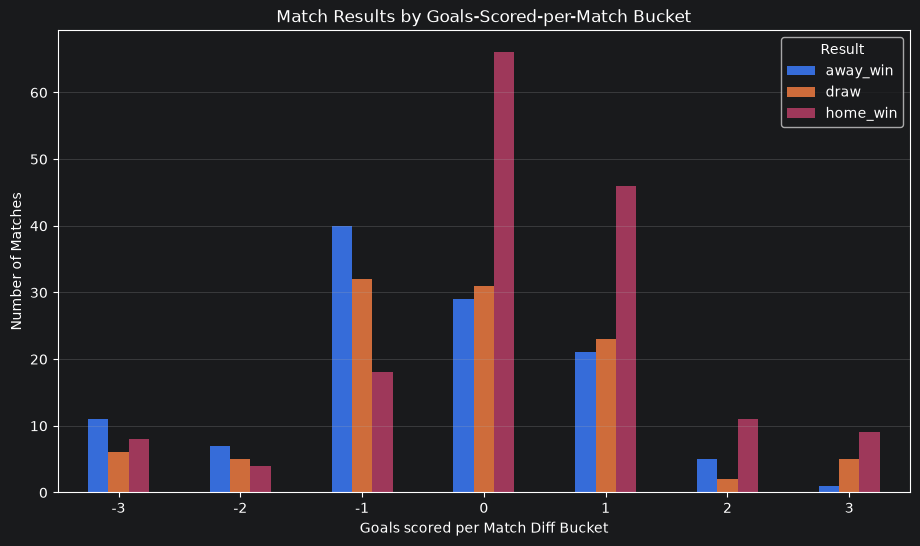

In [4]:
bucket_result = pd.crosstab(
    df["goals_scored_pm_diff_bucket"],
    df["result"]
)

bucket_result.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Match Results by Goals-Scored-per-Match Bucket")
plt.xlabel("Goals scored per Match Diff Bucket")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.legend(title="Result")
plt.grid(axis="y", alpha=0.3)
plt.show()

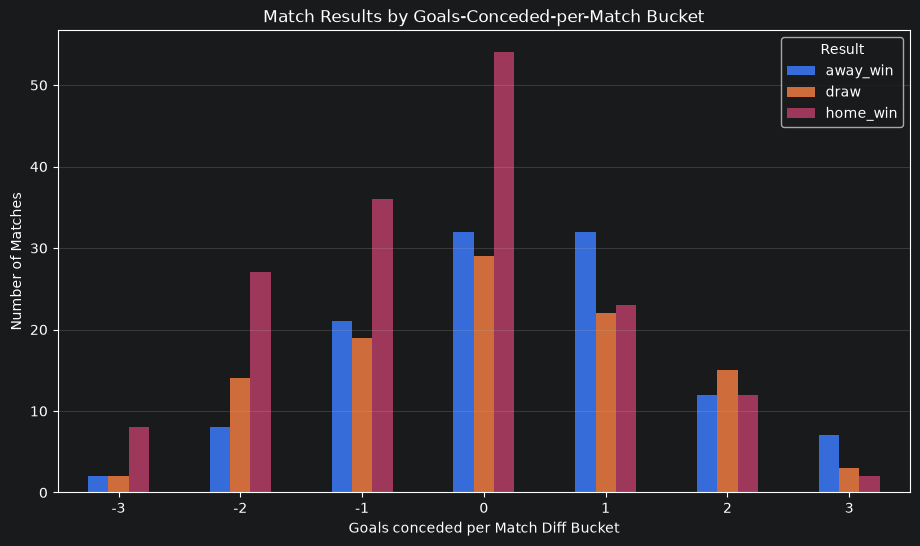

In [5]:
bucket_result = pd.crosstab(
    df["goals_conceded_pm_diff_bucket"],
    df["result"]
)

bucket_result.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Match Results by Goals-Conceded-per-Match Bucket")
plt.xlabel("Goals conceded per Match Diff Bucket")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.legend(title="Result")
plt.grid(axis="y", alpha=0.3)
plt.show()